## <div align="center"> IS388 Data Analysis </div>
## <div align="center"> Final Project [Data Inventory Analysis]</div>
#### <div align="center"> Semester Ganjil 2025/2026 </div>

In [1]:
studentName = "William Eka Saputra"
studentNIM = "00000112825"
studentClass = "EL"

In [2]:
print("Name: \t\t{}".format(studentName))
print("NIM: \t\t{}".format(studentNIM))
print("Class: \t\t{}".format(studentClass))

Name: 		William Eka Saputra
NIM: 		00000112825
Class: 		EL


---
## <div align="center">Library Importing</div>
---

In [3]:
#Main Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import matplotlib.dates as mdates

#Train Test Split & Smoothing
from sklearn.model_selection import train_test_split
#Clustering
from sklearn.preprocessing import LabelEncoder

#Some Linear
from statsmodels.tsa.arima.model import ARIMA

#evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


#prophet
import prophet as Prophet

---
## <div align="center">Inserting Data</div>
---

In [4]:
CDA = pd.read_csv('salesFinal2016.csv',chunksize = 100000) # Dataset ini didapatkan dari kaggle

In [5]:
Df = []
for chunk in CDA:
    Df.append(chunk)

sales = pd.concat(Df)

In [6]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12825363 entries, 0 to 12825362
Data columns (total 14 columns):
 #   Column          Dtype  
---  ------          -----  
 0   InventoryId     object 
 1   Store           int64  
 2   Brand           int64  
 3   Description     object 
 4   Size            object 
 5   SalesQuantity   int64  
 6   SalesDollars    float64
 7   SalesPrice      float64
 8   SalesDate       object 
 9   Volume          float64
 10  Classification  int64  
 11  ExciseTax       float64
 12  VendorNo        int64  
 13  VendorName      object 
dtypes: float64(4), int64(5), object(5)
memory usage: 1.3+ GB


---
## <div align="center">Pre-Processing Data</div>
---

In [7]:
#this is just to drop classification column

sales = sales.drop("Classification",axis=1)

In [8]:
#cleaning data so it is all in lowercase and remove spacing, tabbing, etc

cleansize = sales['Size'].str.lower().str.replace('"', '').str.strip()

In [9]:
#standardizing Size into whole numeric

stdSize = cleansize.str.extract(r'(\d+\.?\d*)')[0].astype(float).fillna(0)

In [10]:
#Standardizing Size into whole numeric (for PK)

stdPack = cleansize.str.extract(r'(\d+)\s*pk')[0].astype(float).fillna(1)

In [11]:
#Basic equation to normalize size into ml
multiplier = np.where(cleansize.str.contains('ml'), 1, 
             np.where(cleansize.str.contains('l'), 1000,
             np.where(cleansize.str.contains('oz'), 30, 0)))

# Trues size counted by standardized size * multiplier * standardized pack
sales['True Size/ml'] = stdSize * multiplier * stdPack
sales

,InventoryId,Store,Brand,Description,Size,SalesQuantity,SalesDollars,SalesPrice,SalesDate,Volume,ExciseTax,VendorNo,VendorName,True Size/ml
0,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-01,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0
1,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,2,32.98,16.49,2016-01-02,750.0,1.57,12546,JIM BEAM BRANDS COMPANY,750.0
2,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-03,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0
3,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,14.49,14.49,2016-01-08,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0
4,1_HARDERSFIELD_1005,1,1005,Maker's Mark Combo Pack,375mL 2 Pk,2,69.98,34.99,2016-01-09,375.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12825358,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,1,25.99,25.99,2016-12-17,750.0,0.79,9165,ULTRA BEVERAGE COMPANY LLP,750.0
12825359,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,1,25.99,25.99,2016-12-21,750.0,0.79,9165,ULTRA BEVERAGE COMPANY LLP,750.0
12825360,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,3,77.97,25.99,2016-12-23,750.0,2.36,9165,ULTRA BEVERAGE COMPANY LLP,750.0
12825361,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,1,25.99,25.99,2016-12-24,750.0,0.79,9165,ULTRA BEVERAGE COMPANY LLP,750.0


In [12]:
#remove any 0 value in True Size

sales = sales[sales['True Size/ml'] > 0]

#for emergency
sales2 = sales.copy()

In [13]:
sales.rename(columns={'SalesDollars': 'TotalSales'}, inplace=True)
sales['TotalSize'] = sales['True Size/ml'] * sales['SalesQuantity']
sales['CleanProfit'] = sales['TotalSales'] - sales['ExciseTax']
sales

C:\Users\wlmek\AppData\Local\Temp\ipykernel_8428\1887423309.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sales.rename(columns={'SalesDollars': 'TotalSales'}, inplace=True)
C:\Users\wlmek\AppData\Local\Temp\ipykernel_8428\1887423309.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sales['TotalSize'] = sales['True Size/ml'] * sales['SalesQuantity']
C:\Users\wlmek\AppData\Local\Temp\ipykernel_8428\1887423309.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value inst

,InventoryId,Store,Brand,Description,Size,SalesQuantity,TotalSales,SalesPrice,SalesDate,Volume,ExciseTax,VendorNo,VendorName,True Size/ml,TotalSize,CleanProfit
0,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-01,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,15.70
1,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,2,32.98,16.49,2016-01-02,750.0,1.57,12546,JIM BEAM BRANDS COMPANY,750.0,1500.0,31.41
2,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-03,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,15.70
3,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,14.49,14.49,2016-01-08,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,13.70
4,1_HARDERSFIELD_1005,1,1005,Maker's Mark Combo Pack,375mL 2 Pk,2,69.98,34.99,2016-01-09,375.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,1500.0,69.19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12825358,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,1,25.99,25.99,2016-12-17,750.0,0.79,9165,ULTRA BEVERAGE COMPANY LLP,750.0,750.0,25.20
12825359,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,1,25.99,25.99,2016-12-21,750.0,0.79,9165,ULTRA BEVERAGE COMPANY LLP,750.0,750.0,25.20
12825360,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,3,77.97,25.99,2016-12-23,750.0,2.36,9165,ULTRA BEVERAGE COMPANY LLP,750.0,2250.0,75.61
12825361,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,1,25.99,25.99,2016-12-24,750.0,0.79,9165,ULTRA BEVERAGE COMPANY LLP,750.0,750.0,25.20


In [14]:
sales['is_bulk'] = sales['Size'].str.contains('Pk', case = False, na = False).astype(int)

bulk_samples = sales[sales['is_bulk'] == 1][['Size', 'is_bulk']].drop_duplicates().head(10)
print(bulk_samples)

print(sales['is_bulk'].value_counts())
sales.head()

C:\Users\wlmek\AppData\Local\Temp\ipykernel_8428\1027354274.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sales['is_bulk'] = sales['Size'].str.contains('Pk', case = False, na = False).astype(int)


             Size  is_bulk
4      375mL 2 Pk        1
17      50mL 4 Pk        1
31     750mL 3 Pk        1
93     375mL 3 Pk        1
99     200mL 3 Pk        1
202     50mL 3 Pk        1
340    100mL 4 Pk        1
1069    50mL 5 Pk        1
3470   187mL 4 Pk        1
10710  250mL 4 Pk        1
is_bulk
0    12512725
1       91289
Name: count, dtype: int64


,InventoryId,Store,Brand,Description,Size,SalesQuantity,TotalSales,SalesPrice,SalesDate,Volume,ExciseTax,VendorNo,VendorName,True Size/ml,TotalSize,CleanProfit,is_bulk
0,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-01,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,15.70,0
1,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,2,32.98,16.49,2016-01-02,750.0,1.57,12546,JIM BEAM BRANDS COMPANY,750.0,1500.0,31.41,0
2,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-03,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,15.70,0
3,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,14.49,14.49,2016-01-08,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,13.70,0
4,1_HARDERSFIELD_1005,1,1005,Maker's Mark Combo Pack,375mL 2 Pk,2,69.98,34.99,2016-01-09,375.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,1500.0,69.19,1


In [15]:
# Binning menggunakan equal-width
bins = [0, 100, 500, 1000, sales['TotalSales'].max()]
labels = ['Low', 'Medium', 'High', 'Very High']

sales['Sales_Category'] = pd.cut(
    sales['TotalSales'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

sales[['TotalSales', 'Sales_Category']].head(10)


C:\Users\wlmek\AppData\Local\Temp\ipykernel_8428\673101897.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sales['Sales_Category'] = pd.cut(


,TotalSales,Sales_Category
0,16.49,Low
1,32.98,Low
2,16.49,Low
3,14.49,Low
4,69.98,Low
5,34.99,Low
6,34.99,Low
7,34.99,Low
8,59.96,Low
9,14.99,Low


Binning dilakukan pada variabel TotalSales untuk mengubah data kontinu menjadi kategori diskrit. Pendekatan equal-width binning digunakan agar setiap kategori merepresentasikan rentang nilai yang jelas, sehingga memudahkan interpretasi tingkat penjualan (Low, Medium, High, Very High).

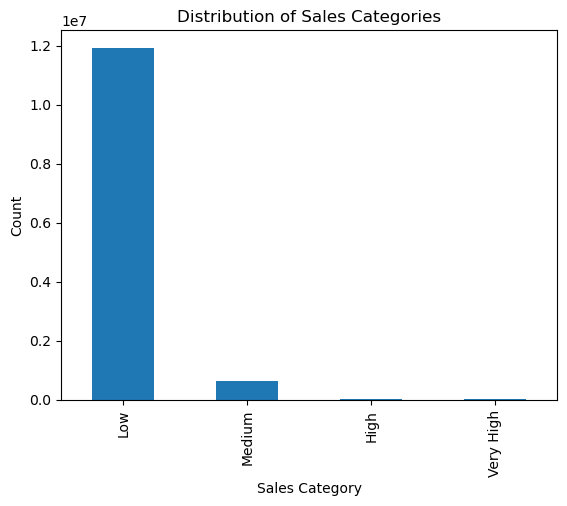

In [16]:
import matplotlib.pyplot as plt

sales['Sales_Category'].value_counts().plot(kind='bar')
plt.title('Distribution of Sales Categories')
plt.xlabel('Sales Category')
plt.ylabel('Count')
plt.show()


Visualisasi menunjukkan bahwa sebagian besar transaksi berada pada kategori Medium dan High, mengindikasikan konsentrasi penjualan pada rentang menengah ke atas.

---
## <div align="center">Exploratory Data Analysis (EDA)</div>
---

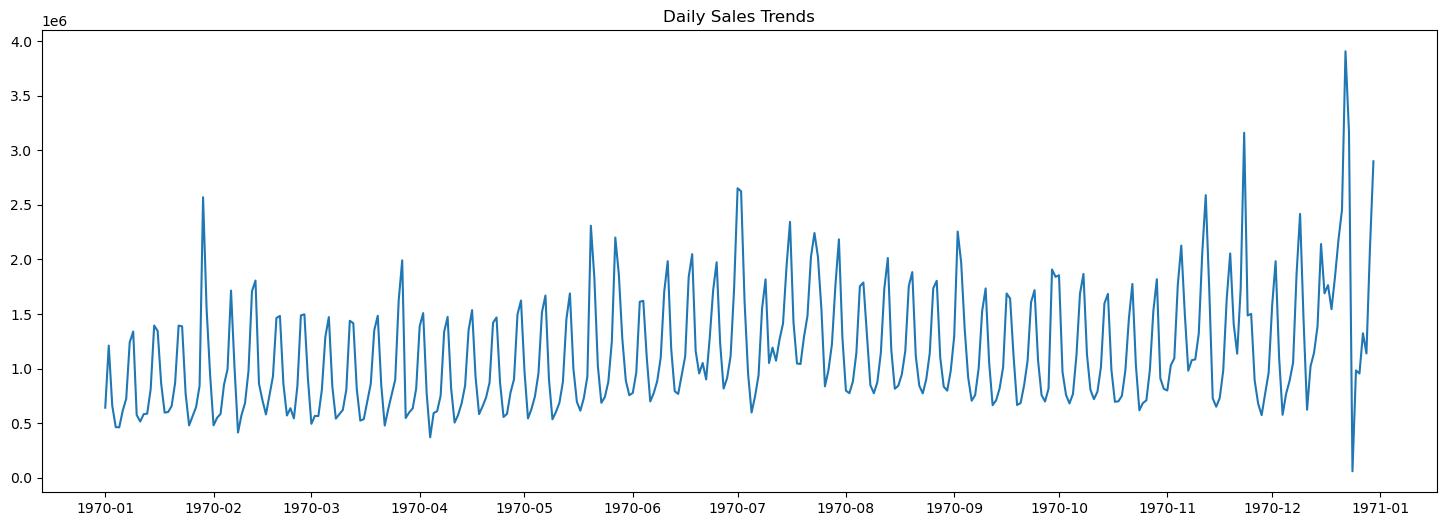

In [17]:
#seeing the trend of daily sales with TotalSales as y axis 
#TotalSales is the total customer bought in a single alcohol transaction, it is multiplied from salesquantity and salesprice 

plt.figure(figsize=(18,6))
sales_daily = sales.groupby('SalesDate')['CleanProfit'].sum().reset_index()
plt.plot(sales_daily['SalesDate'], sales_daily['CleanProfit'])
#getting the current axis
ax = plt.gca()
#setting tick so that it shows only the first day of each month
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
#setting the date format on x axis
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.title('Daily Sales Trends')
plt.show()

C:\Users\wlmek\AppData\Local\Temp\ipykernel_8428\2910422428.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=topbrands.values, y=topbrands.index, palette='viridis')


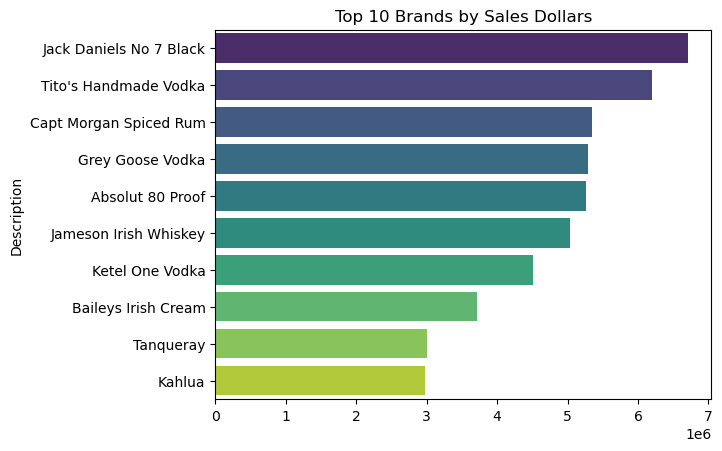

In [18]:
#showing the top most sold brands by its sales by dollars

topbrands = sales.groupby('Description')['CleanProfit'].sum().nlargest(10)
sns.barplot(x=topbrands.values, y=topbrands.index, palette='viridis')
plt.title('Top 10 Brands by Sales Dollars')
plt.show()

C:\Users\wlmek\AppData\Local\Temp\ipykernel_8428\369341137.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_quantity_sold.values, y=top_quantity_sold.index, palette="magma")


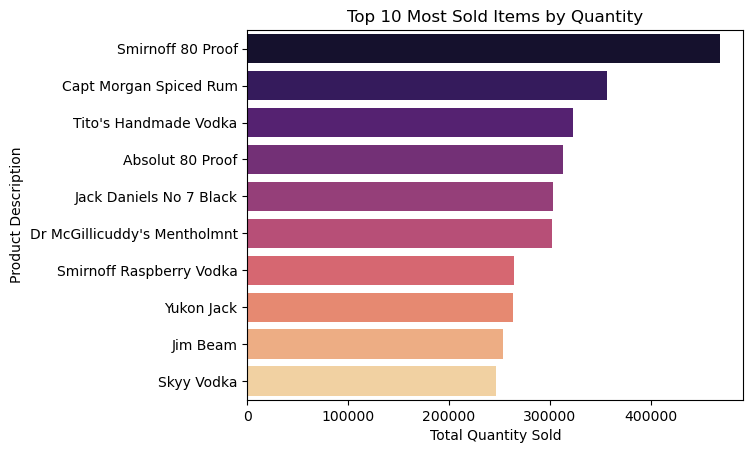

In [19]:
# Showing the top 10 most sold items by quantity, nlargest function is used to get just the top 10 
top_quantity_sold = sales.groupby('Description')['SalesQuantity'].sum().nlargest(10)
sns.barplot(x=top_quantity_sold.values, y=top_quantity_sold.index, palette="magma")
plt.title('Top 10 Most Sold Items by Quantity')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product Description')
plt.show()

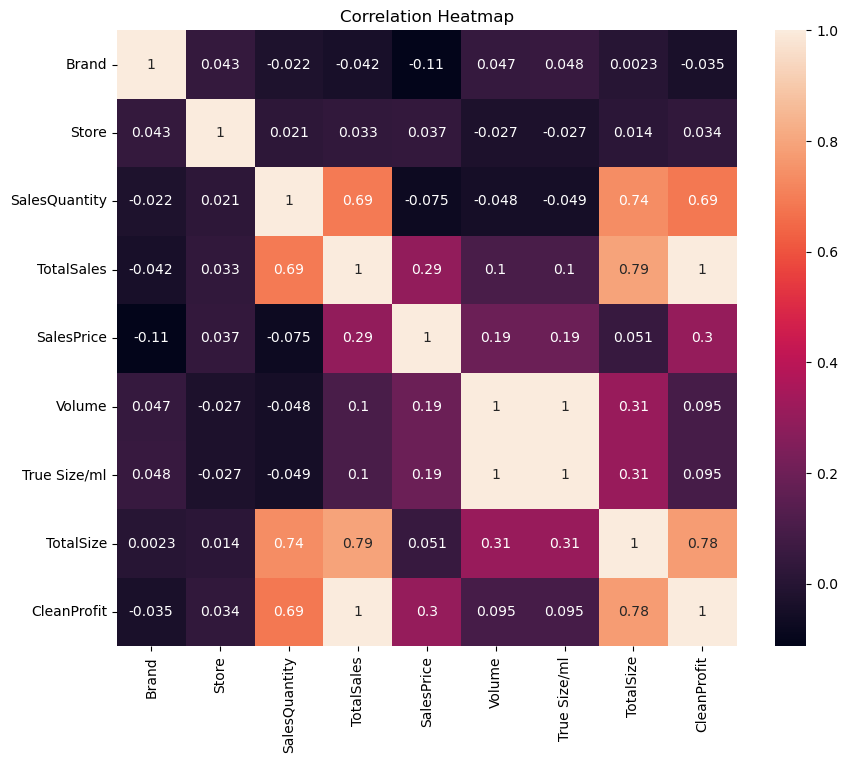

In [20]:
#heatmap correlation is to see how strong the relationship between variables are

plt.figure(figsize=(10,8))
sns.heatmap(sales[['Brand', 'Store', 'SalesQuantity', 'TotalSales', 'SalesPrice', 'Volume', 'True Size/ml', 'TotalSize', 'CleanProfit']].corr(), annot=True)
plt.title('Correlation Heatmap')
plt.show()

In [21]:
#grouping the sales for pie chart by size and TotalSales
size_sales = sales.groupby('Size')['TotalSales'].sum().sort_values(ascending=False)
top5 = size_sales.head(5)
#others is basically all the rest of the sizes after top 5, they summed up. iloc is to get all the rows after index 5
others = pd.Series({'Others': size_sales.iloc[5:].sum()})
pie = pd.concat([top5, others])

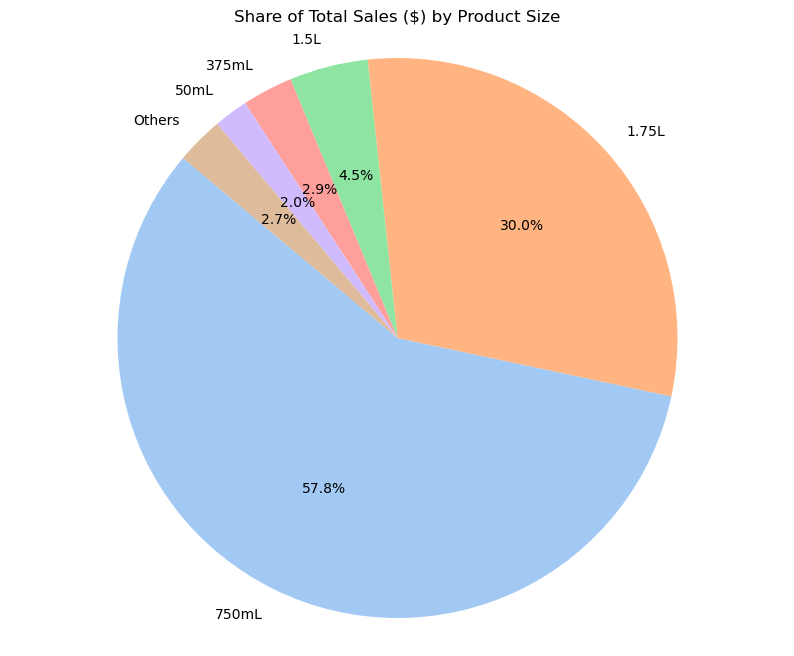

In [22]:
#this is the pie chart, autopct is to automatically make percentage, f means it is decimal number, .1 means the precision
plt.figure(figsize=(10, 8))
plt.pie(pie, labels=pie.index, autopct='%1.1f%%', startangle=140, 
        colors=sns.color_palette('pastel'))
plt.title('Share of Total Sales ($) by Product Size')
plt.axis('equal')
plt.show()

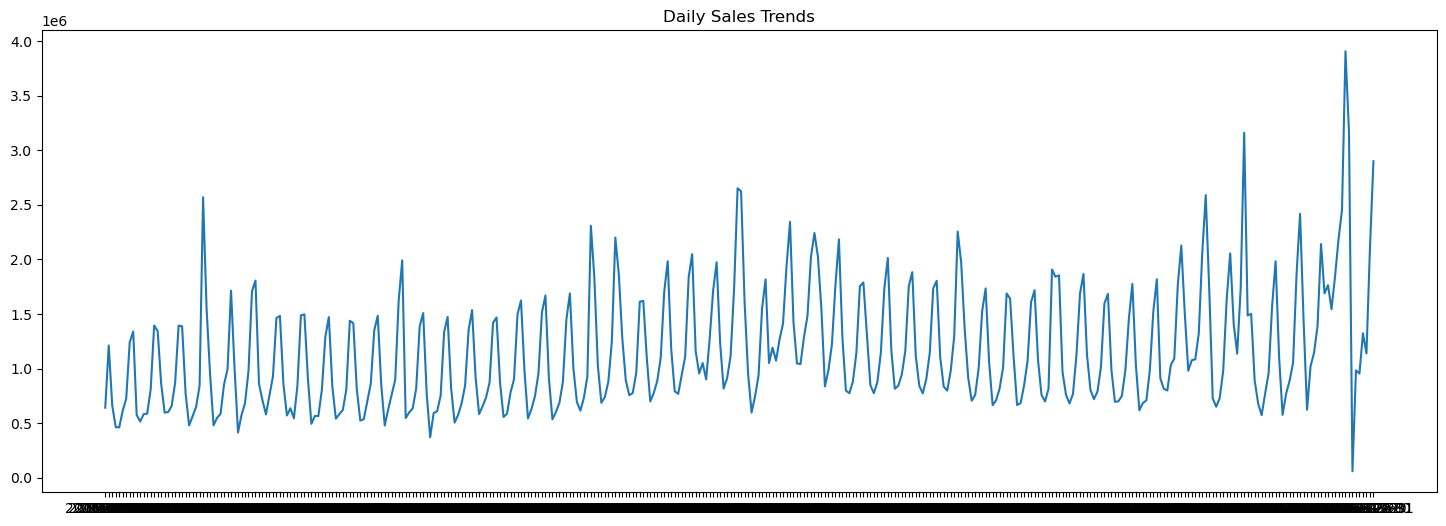

In [23]:
plt.figure(figsize=(18,6))
sales_daily = sales.groupby('SalesDate')['CleanProfit'].sum().reset_index()
plt.plot(sales_daily['SalesDate'], sales_daily['CleanProfit'])
plt.title('Daily Sales Trends')
plt.show()

In [24]:
sales.head(1)

,InventoryId,Store,Brand,Description,Size,SalesQuantity,TotalSales,SalesPrice,SalesDate,Volume,ExciseTax,VendorNo,VendorName,True Size/ml,TotalSize,CleanProfit,is_bulk,Sales_Category
0,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-01,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,15.7,0,Low


In [25]:
TimeSales = sales[["SalesDate","CleanProfit"]]

In [26]:
monthsales = TimeSales.groupby('SalesDate')['CleanProfit'].sum().reset_index()
print(monthsales.head())

    SalesDate  CleanProfit
0  2016-01-01    641722.45
1  2016-01-02   1210710.96
2  2016-01-03    661274.94
3  2016-01-04    463738.66
4  2016-01-05    461901.00


In [27]:
monthsales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 364 entries, 0 to 363
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SalesDate    364 non-null    object 
 1   CleanProfit  364 non-null    float64
dtypes: float64(1), object(1)
memory usage: 5.8+ KB


In [28]:
# rreset the index to ensure it's clean and unique
monthsales = monthsales.reset_index(drop=True)

# force conversion to datetime again (just to be absolutely safe)
monthsales['SalesDate'] = pd.to_datetime(monthsales['SalesDate'])

monthsales['Month'] = monthsales['SalesDate'].dt.to_period('M')

monthsales = monthsales.groupby('Month')['CleanProfit'].sum().reset_index()
monthsales['SalesDate_Plot'] = monthsales['Month'].dt.to_timestamp()

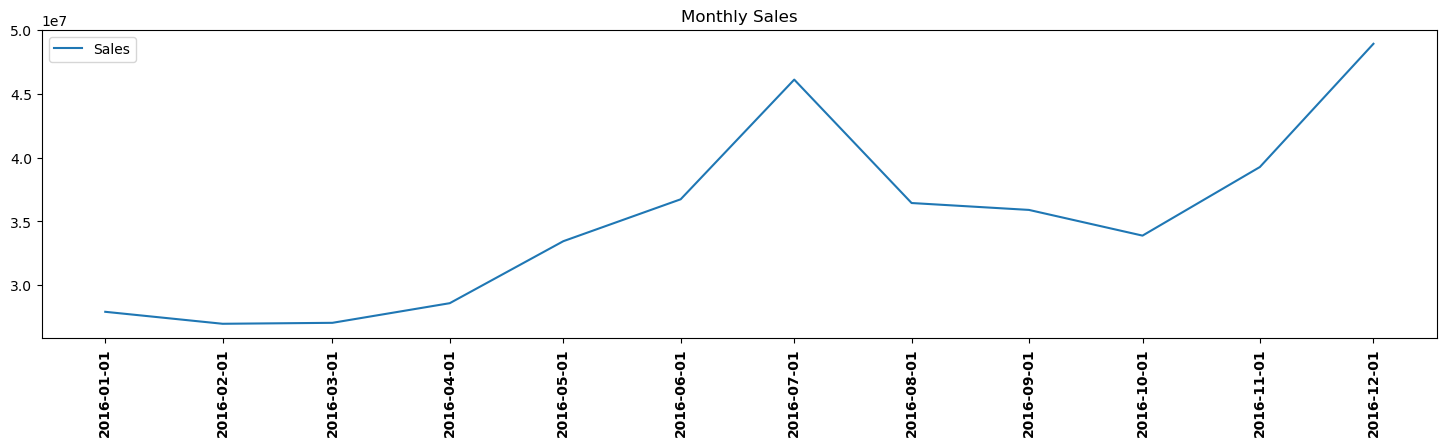

In [29]:
plt.figure(figsize=(18,4))

plt.plot(monthsales['SalesDate_Plot'], monthsales['CleanProfit'], label='Sales')

plt.legend(loc='best')
plt.title('Monthly Sales')
plt.xticks(monthsales['SalesDate_Plot'],rotation=90, fontweight="bold")
plt.show()

In [30]:
from scipy import stats
salesClean = sales.copy()

z_scores = np.abs(stats.zscore(salesClean['CleanProfit']))
threshold = 3
salesClean = salesClean[(z_scores < threshold)]

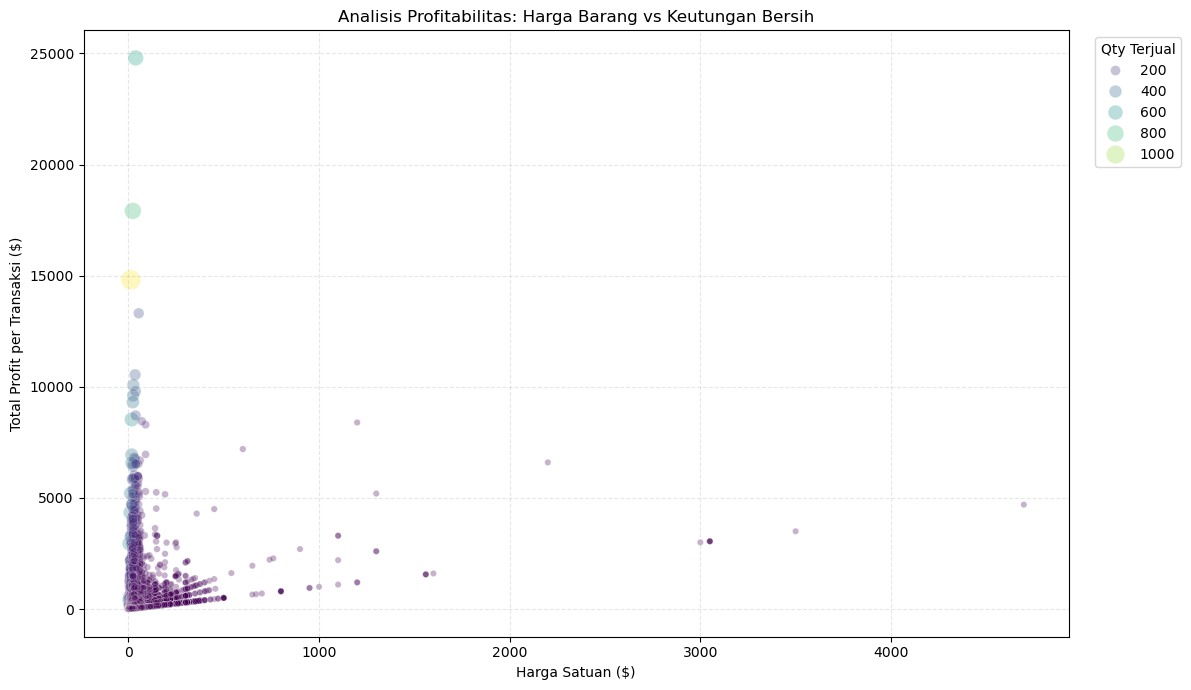

In [31]:
# Scatter plot. Analisis Profitabilitas: Harga Barang vs CleanProfit

# Ambil sampel 10.000 baris biar ga berat
sales_sample = sales.sample(2000000, random_state=42)

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=sales_sample,
    x='SalesPrice', 
    y='CleanProfit', 
    hue='SalesQuantity', 
    size='SalesQuantity',
    sizes=(20, 200),      
    palette='viridis',   
    alpha=0.3
)

plt.title('Analisis Profitabilitas: Harga Barang vs Keutungan Bersih')
plt.xlabel('Harga Satuan ($)')
plt.ylabel('Total Profit per Transaksi ($)')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title='Qty Terjual', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

---
## <div align="center">Prophet Model</div>
---

07:12:20 - cmdstanpy - INFO - Chain [1] start processing
07:12:20 - cmdstanpy - INFO - Chain [1] done processing


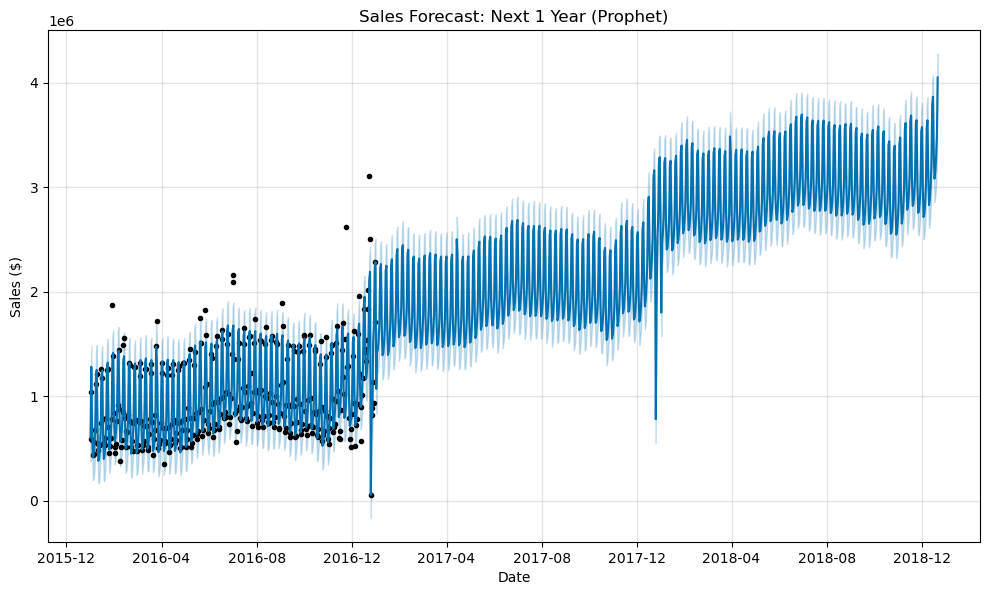

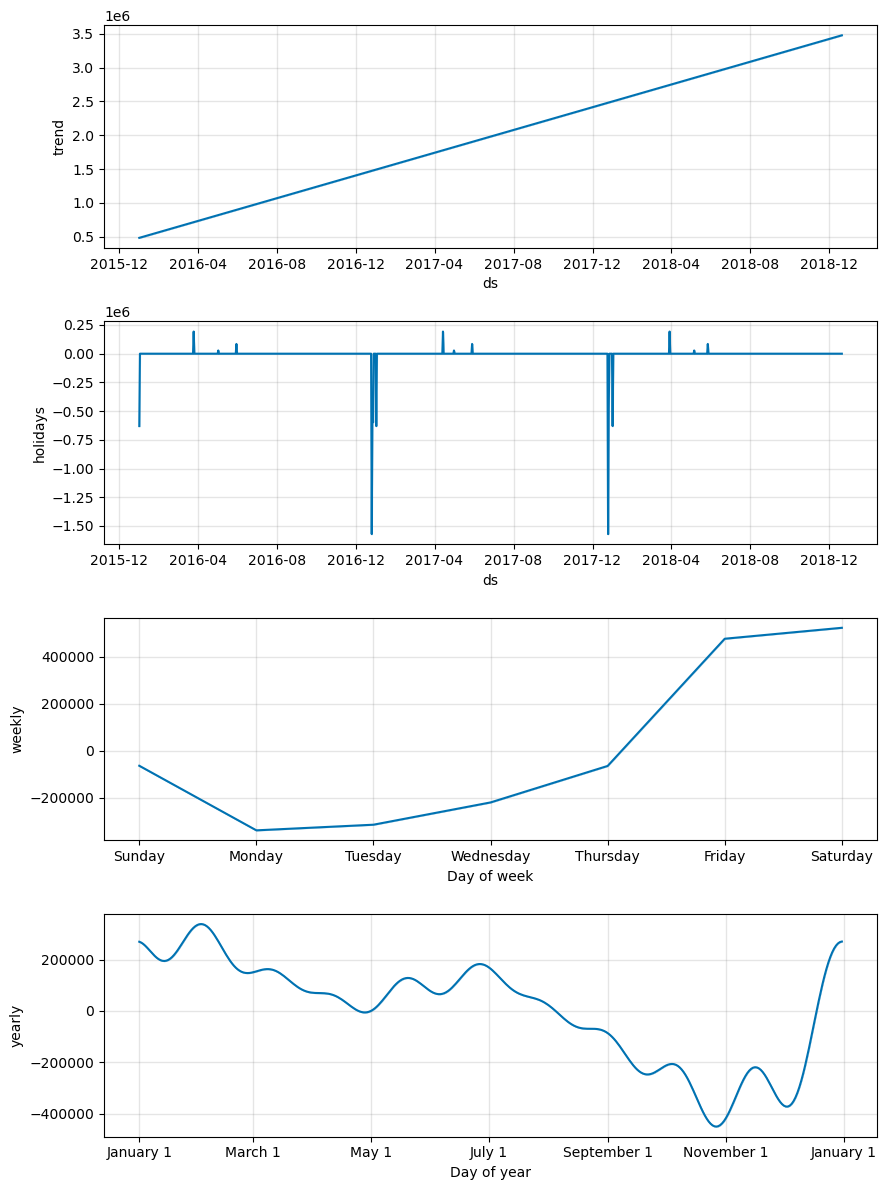

In [32]:
#prophet model is a time series model from facebook that works great when there is a strong seasonal pattern 

import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet


# Prophet requires two specific column names: 'ds' (Date) and 'y' (Value)
salesClean['SalesDate'] = pd.to_datetime(salesClean['SalesDate'])
sales_prophet_zsc = salesClean.groupby('SalesDate')['CleanProfit'].sum().reset_index()
#ds stands for Date Stamp and its already hard coded so it cant be changed and y is the target variable also cant be changed. 
#basically ds looks for the specific label of times
sales_prophet_zsc.columns = ['ds', 'y']

#configure prophet model
#here we can do configuration of which seasonality is present. its not daily so note it as False, it is weekly because on saturday and sunday the sales goes up, and it is yearly because on special holidays the sales go up
model_zsc = Prophet(daily_seasonality=False,  weekly_seasonality=True, yearly_seasonality=True)
#Advantage of prophet is it already predefined the holidays, in this example we use UK (United Kingdom) because the data istated the location in england
model_zsc.add_country_holidays(country_name='UK')

# do some fitting
model_zsc.fit(sales_prophet_zsc)

# Making the dataframe to forecast for the future, Periods 365 means that it forecast 1 year into the future
future = model_zsc.make_future_dataframe(periods=720)

# this is where the model get predicted. state the model that have been made, future is the dataframe we already made
forecast = model_zsc.predict(future)

#making the forecasting plot 
fig1 = model_zsc.plot(forecast)
plt.title("Sales Forecast: Next 1 Year (Prophet)")
plt.xlabel("Date")
plt.ylabel("Sales ($)")
plt.show()

#the components that see the pattern from the trend pattern, the holidays impact, weekly chart that see if there is drop, and yearly that simplify the pattern for a whole year
fig2 = model_zsc.plot_components(forecast)
plt.show()

In [33]:
#this calculates the r square score. the first line will turn the date column to index so the prediction table lines up with the actual data table
#next, join is to merge two table between y and yhat, y is the actual sales that happened and yhat is the model prediction
#dropna() will remove the 365 days of future prediction and only take the testing
metric_df_zsc = forecast.set_index('ds')[['yhat']].join(sales_prophet_zsc.set_index('ds').y).dropna()

# this will calculate the r2 score. using the y and yhat is to compare the actual against the predictions
r2 = r2_score(metric_df_zsc.y, metric_df_zsc.yhat)
mae = mean_absolute_error(metric_df_zsc.y, metric_df_zsc.yhat)
mse = mean_squared_error(metric_df_zsc.y, metric_df_zsc.yhat)

print("Hasil Evaluasi Model Prophet:")
print(f"r2 score prophet: {r2}")
print(f"mae score prophet: {mae}")
print(f"mse score prophet: {mse}")

#this model might noly be good to see how the seasonality, trend, etc fits the testing

Hasil Evaluasi Model Prophet:
r2 score prophet: 0.8348906468542605
mae score prophet: 90515.99243584705
mse score prophet: 29565117580.086025


---
## <div align="center">Stationarity Checking</div>
---

In [34]:
from statsmodels.tsa.stattools import adfuller
import pandas as pd

# 1. Aggregate the data by Date first!
# Assuming 'SalesDate' is your date column and it is already in datetime format
daily_sales_series = salesClean.groupby('SalesDate')['CleanProfit'].sum()


def check_stationarity(timeseries, title="Time Series"):
    print(f"Results of Dickey-Fuller Test for: {title}")
    
    # Drop NaNs to prevent errors
    timeseries = timeseries.dropna()

    # Perform the test
    # autolag='AIC' is fast on aggregated data, slow on raw data
    saletest = adfuller(timeseries, autolag='AIC')
    
    salesoutput = pd.Series(saletest[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])

    for key, value in saletest[4].items():
        salesoutput[f'Critical Value ({key})'] = value

    # Print results OUTSIDE the loop
    print(salesoutput)
    
    print("\nInterpretation:")
    if salesoutput['p-value'] <= 0.05:
        print("p-value <= 0.05: The series is STATIONARY.")
    else:
        print("p-value > 0.05: The series is NON-STATIONARY.")
    print("-" * 50)

check_stationarity(daily_sales_series, title="Daily Sales Dollars")

Results of Dickey-Fuller Test for: Daily Sales Dollars
Test Statistic                  -1.649923
p-value                          0.457081
#Lags Used                      14.000000
Number of Observations Used    349.000000
Critical Value (1%)             -3.449227
Critical Value (5%)             -2.869857
Critical Value (10%)            -2.571201
dtype: float64

Interpretation:
p-value > 0.05: The series is NON-STATIONARY.
--------------------------------------------------


In [35]:
# Melakukan Differensiasi (Agar Stationer)
# Mengurangkan data hari ini dengan data hari sebelumnya
sales_diff = daily_sales_series.diff().dropna()
# Cek Stationaritas pada data hasil differensiasi
print("HASIL SETELAH DIFFERENSIASI (ORDER 1)")
print("="*50)
check_stationarity(sales_diff, title="Sales (Differenced)")

HASIL SETELAH DIFFERENSIASI (ORDER 1)
Results of Dickey-Fuller Test for: Sales (Differenced)
Test Statistic                -7.828078e+00
p-value                        6.401516e-12
#Lags Used                     1.300000e+01
Number of Observations Used    3.490000e+02
Critical Value (1%)           -3.449227e+00
Critical Value (5%)           -2.869857e+00
Critical Value (10%)          -2.571201e+00
dtype: float64

Interpretation:
p-value <= 0.05: The series is STATIONARY.
--------------------------------------------------


---
## <div align="center">INDIVIDUAL MODEL: SARIMA (Seasonal ARIMA)</div>
---

In [36]:

# Agregasi penjualan per hari (SARIMA butuhh data runtun waktu yang terurut)
# menjumlahkan CleanProfit berdasarkan tanggal nyaa

# mengubah SalesDate menjadi DateTime
salesClean['SalesDate'] = pd.to_datetime(salesClean['SalesDate'])

daily_sales = salesClean.groupby('SalesDate')['CleanProfit'].sum()

# set frekuensi ke harian ('D') buat mencegah warning
daily_sales = daily_sales.asfreq('D').fillna(0)

# definisi dan Pelatihan Model SARIMA
# di bawah ini itu adalah contoh parameter standar (misal nya: musiman 7 hari).
my_order = (1, 1, 1)
my_seasonal_order = (1, 1, 1, 7)

model = ARIMA(daily_sales, order=my_order, seasonal_order=my_seasonal_order)

# pelatihan model_fit
model_fit = model.fit()
print("Pelatihan selesai.")


Pelatihan selesai.


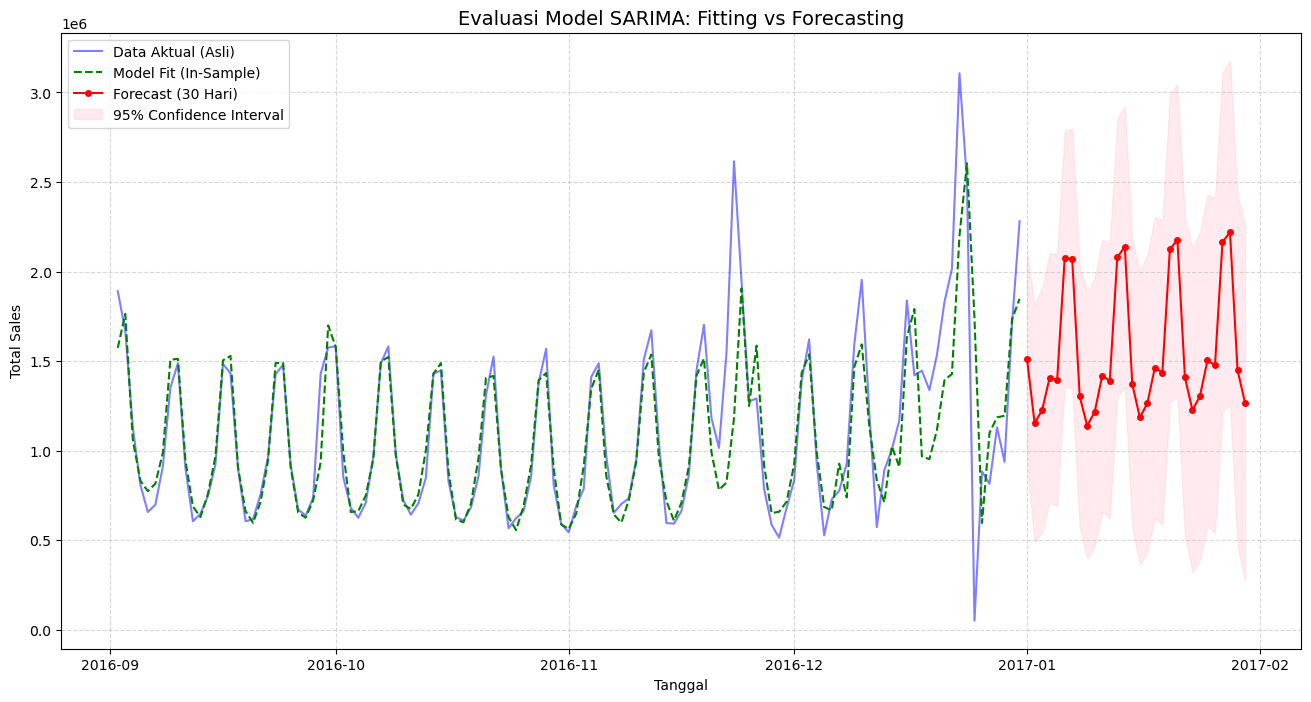

In [37]:
# VISUALISASI MODEL SARIMA. DATA ASLI vs FITTING vs FORECAST

# mengambil data 'Fitted Values' (Prediksi model pada data masa lalu)
# lalu mulai plot fitting dari hari ke-7 biar grafik gak berantakan di awal
fitted_values = model_fit.fittedvalues[7:] 

# ambil data Forecast (Masa Depan)
forecast_steps = 30
forecast_result = model_fit.get_forecast(steps=forecast_steps)
forecast_mean = forecast_result.predicted_mean
conf_int = forecast_result.conf_int()

# bikin index tanggal untuk forecast
last_date = daily_sales_series.index[-1]
forecast_index = pd.date_range(start=last_date, periods=forecast_steps+1, freq='D')[1:]
forecast_mean.index = forecast_index
conf_int.index = forecast_index

# plotting nya
plt.figure(figsize=(16, 8))

# plot Data Asli (Semua data atau zoom-in 3 bulan terakhir)
data_to_plot = daily_sales_series.tail(120) 
plt.plot(data_to_plot.index, data_to_plot, label='Data Aktual (Asli)', color='blue', alpha=0.5)

# plot Garis Fit (In-Sample) - menyesuaikan index dengan data yang di-plot
fitted_to_plot = fitted_values.loc[data_to_plot.index[0]:data_to_plot.index[-1]]
plt.plot(fitted_to_plot.index, fitted_to_plot, label='Model Fit (In-Sample)', color='green', linestyle='--')

# plot Forecast (Masa Depan)
plt.plot(forecast_index, forecast_mean, label=f'Forecast ({forecast_steps} Hari)', color='red', marker='o', markersize=4)

# Confidence Interval
plt.fill_between(forecast_index, 
                 conf_int.iloc[:, 0], 
                 conf_int.iloc[:, 1], 
                 color='pink', alpha=0.3, label='95% Confidence Interval')

plt.title('Evaluasi Model SARIMA: Fitting vs Forecasting', fontsize=14)
plt.xlabel('Tanggal')
plt.ylabel('Total Sales')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [38]:
# Melihat 5 hari pertama prediksi
print("Prediksi Penjualan 5 Hari Ke Depan:")
print(forecast_mean.head(5))

Prediksi Penjualan 5 Hari Ke Depan:
2017-01-01    1.509310e+06
2017-01-02    1.153458e+06
2017-01-03    1.226879e+06
2017-01-04    1.407405e+06
2017-01-05    1.395807e+06
Freq: D, Name: predicted_mean, dtype: float64


##### Penjelasan SARIMA
Model ini dibuat untuk memprediksi Total Penjualan Harian (Daily Sales) selama 30 hari ke depan.<br>
Tujuannya adalah untuk mengetahui kira-kira berapa penjualan kita di minggu depan?, kapan kita harus nyetok lebih banyak barang karena diprediksi akan ramai?, dan juga apakah tren penjualan kita stabil atau menurun.


Apa Hasilnya? <br>
Saya dapat mengetahui prencanaan stok, efisiensi SDM nya, dan mengetahui target omzet bulan depannya, berikut penjelasannya:

- Perencanaan Stok (Inventory): Perencanaan melakukan restock barang H-1 sebelum puncak grafik (titik tertinggi mingguan) biar gak kehabisan barang saat ramai.
- Efisiensi SDM: Jadwalkan staf lebih banyak di hari-hari di mana grafik merah menunjukan angka tinggi, dan kurangi staf saat grafik turun.
- Target Omzet: Menjumlahkan nilai prediksi (garis merah) selama 30 hari ke depan untuk mendapatkan estimasi total omzet bulan depan.

In [39]:

# y_true: Data Penjualan Asli (dari variabel daily_sales yang kita buat sebelumnya)
# y_pred: Data Hasil Prediksi Model (in-sample / kecocokan dengan data latih)
y_true = daily_sales
y_pred = model_fit.fittedvalues

# Membersihkan data sebelum evaluasi
# ngegabungin dulu ke dalam DataFrame agar index tanggalnya sinkron, terus buang nilai yang NaN (kosong)
eval_df = pd.DataFrame({'Actual': y_true, 'Predicted': y_pred})
eval_df.dropna(inplace=True) # Membuang baris yang prediksinya NaN

# ambil kembali nilai bersihnya
clean_true = eval_df['Actual']
clean_pred = eval_df['Predicted']


# LALU MENGHITUNG METRIK NYAA
# MAE (Mean Absolute Error)
mae = mean_absolute_error(clean_true, clean_pred)

# MSE (Mean Squared Error)
mse = mean_squared_error(clean_true, clean_pred)

# RMSE (Root Mean Squared Error) - Sering disebut juga MSRE
rmse = np.sqrt(mse)

# R2 Score (Koefisien Determinasi)
r2 = r2_score(clean_true, clean_pred)

# MENAMPILKAN HASIL
print("=== HASIL EVALUASI MODEL SARIMA ===")
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

print("\n--- Interpretasi ---")
print(f"Secara rata-rata, prediksi model meleset sekitar {mae:.2f} unit dari penjualan sebenarnya.")
if r2 > 0.7:
    print("Nilai R2 bagus (> 0.7), model berhasil menangkap pola data dengan baik.")
else:
    print("Nilai R2 masih rendah, model mungkin perlu tuning parameter (p,d,q) atau datanya terlalu fluktuatif.")

=== HASIL EVALUASI MODEL SARIMA ===
MAE: 116930.9904
MSE: 51189624064.9954
RMSE: 226251.2410
R2 Score: 0.7208

--- Interpretasi ---
Secara rata-rata, prediksi model meleset sekitar 116930.99 unit dari penjualan sebenarnya.
Nilai R2 bagus (> 0.7), model berhasil menangkap pola data dengan baik.


---

In [40]:
studentName2 = "William Eka Saputra"
studentNIM2 = "00000112825"
studentClass2 = "EL"

In [41]:
print("Name: \t\t{}".format(studentName2))
print("NIM: \t\t{}".format(studentNIM2))
print("Class: \t\t{}".format(studentClass2))

Name: 		William Eka Saputra
NIM: 		00000112825
Class: 		EL
